# 1. Business problem

### A telecommunicaton company wants to reduce customer churn.The company has historical customer information and knows whether each customer eventually left(Churn=Yes) or stayed (Churn=No)

## The objective is:

### Build a model that predicts the probability that a customer will churn, allowing the company to identify high risk customers and tak take retenion action before they leave

In [ ]:
# import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

In [ ]:
# load the dataset
df = pd.read_csv('Telco_Churn_Dataset.csv')

In [ ]:
# preview
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Dataset size
df.shape

(7043, 21)

In [ ]:
#Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# check for missing values
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## Data Cleaning

In [ ]:
df['Total Charges']=pd.to_numeric(
    df['TotalCharges'],errors='coerce'
)

In [ ]:
#recheck for missing values
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
#remove missing values
df = df.dropna()

In [ ]:
#check for duplicates
df.duplicated().sum()

np.int64(0)

In [ ]:
# remove the customer ID column
df.drop('customerID', axis=1) #not useful for predicting churn

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Total Charges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.5,No,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,151.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No,1990.50
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No,7362.90
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,346.45
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes,306.60


Explore the target variable

In [ ]:
df['Churn'].value_counts()

,count
Churn,
No,5163
Yes,1869


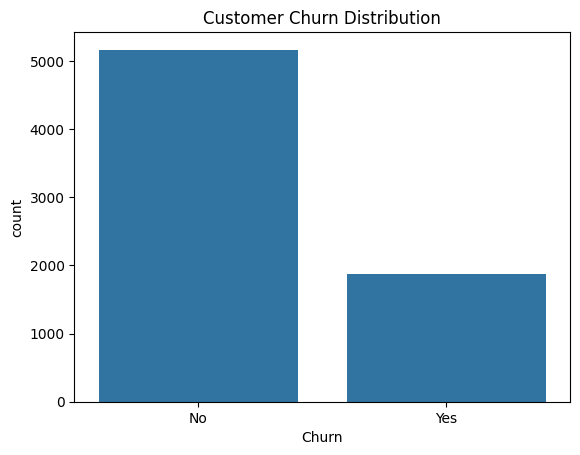

In [ ]:
sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.show()

Class Distribution:
1. No(Non-churners):73.4%
1. Yes(Churners)26.4%

### Explore Churn against important variables

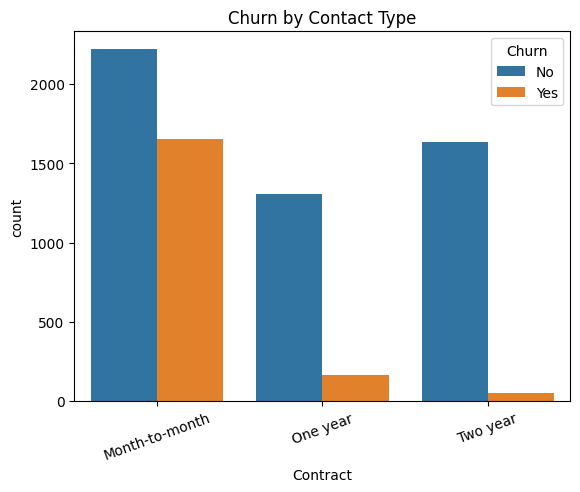

In [ ]:
# Contract type
sns.countplot(data=df, x='Contract',hue='Churn')

plt.title('Churn by Contact Type')
plt.xticks(rotation=20)
plt.show()

## Customers on month -to-month contracts churn more frequently than customers on longer contracts

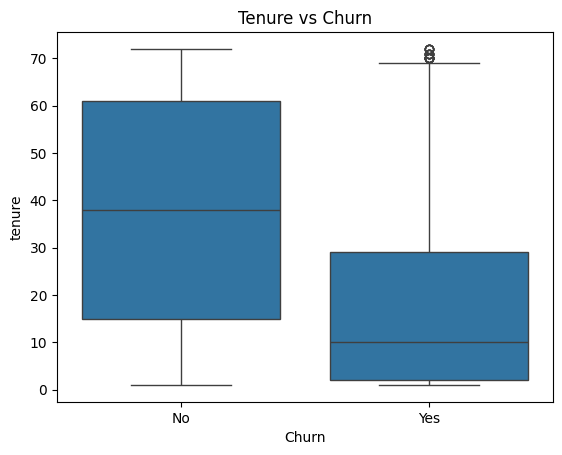

In [ ]:
# Tenure
sns.boxplot(data = df,x='Churn', y='tenure')
plt.title('Tenure vs Churn')
plt.show()

**Customers who leave tend to have  shorter relationship(tenure)with the company**

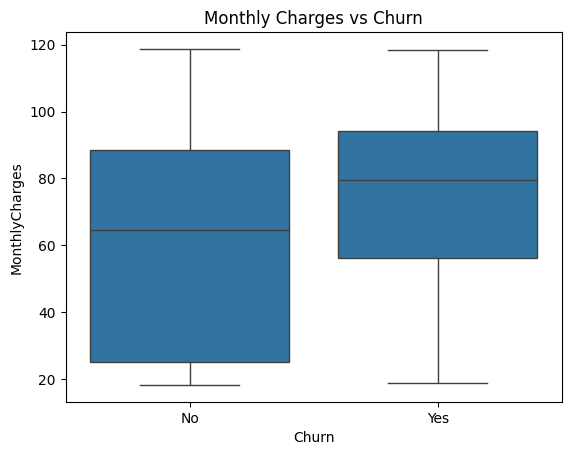

In [ ]:
# Monthly charges
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Monthly Charges vs Churn')
plt.show()

Customers paying higher monthly charges are more likely to leave.

## Prepare the target variable

###**Machine learning algorithms do not understand :yes or no**

###**So we convert them into :1 or 0**

In [ ]:
df['Churn'] = df['Churn'].map(
    {
        'Yes':1,
        'No':0
    }
)

In [ ]:
df['Churn'].value_counts()

,count
Churn,
0,5163
1,1869


## Seperate X(Featres) and y(target)

In [ ]:
# Features
X=df.drop('Churn',axis=1)
#Target variable
y=df['Churn']

## Convert categorical variable

In [ ]:
# One hot encoding
X = pd.get_dummies(X, drop_first=True,dtype=int)

In [ ]:
X.head()

,SeniorCitizen,tenure,MonthlyCharges,Total Charges,customerID_0003-MKNFE,customerID_0004-TLHLJ,customerID_0011-IGKFF,customerID_0013-EXCHZ,customerID_0013-MHZWF,customerID_0013-SMEOE,...,TotalCharges_995.35,TotalCharges_996.45,TotalCharges_996.85,TotalCharges_996.95,TotalCharges_997.65,TotalCharges_997.75,TotalCharges_998.1,TotalCharges_999.45,TotalCharges_999.8,TotalCharges_999.9
0,0,1,29.85,29.85,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,34,56.95,1889.50,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,2,53.85,108.15,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,45,42.30,1840.75,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Train-test Split

In [ ]:
X_train, X_test,y_train,y_test=train_test_split(X,y, test_size=0.2, stratify=y, random_state=42)

random_state=42 - reproduceability of the split

stratify=y to maintain appximately the same churn/non-churn proportion in both datasets.

##  Scale Numerical Features

### For example
### tenure 1-72

### monthlycharges 20-120

### totalcharges 20-8000

**The scales are very different**

In [ ]:
# Intialize the scaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

We use fit_transform on training data only and transform on testing data.Because we don't want information from the test set influencing the training process.

Thus preventing data leakage.

## Train logistic Regression

In [ ]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train) # Learns relationship between customer characteristic and the probablilty of churn

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = model.predict(X_test_scaled)

## Model Predictions

In [ ]:
# Predict Probability
y_prob = model.predict_proba(X_test_scaled)[:,1] # returns probability of churn

# convert probability to class labels
y_pred = (y_prob >=0.5).astype(int)
# Threshold = 0.5
# if probability >0.5 -> Churn

## Model Evaluation

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy:', accuracy * 100)

Accuracy: 76.26154939587776


In [ ]:
# Classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.77      0.97      0.86      1033
           1       0.69      0.19      0.30       374

    accuracy                           0.76      1407
   macro avg       0.73      0.58      0.58      1407
weighted avg       0.75      0.76      0.71      1407



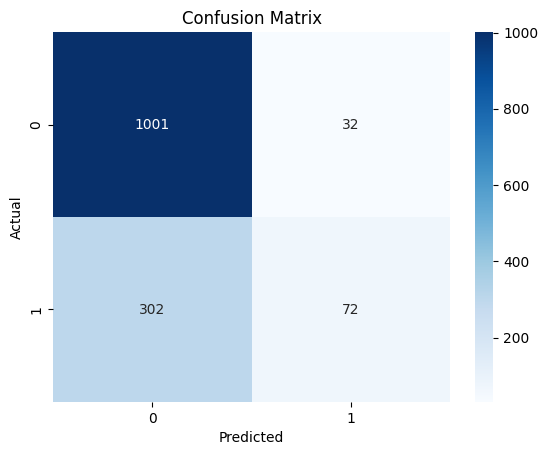

In [ ]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
  )

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### ROC-AUC

In [ ]:
auc = roc_auc_score(y_test, y_pred)

print('AUC:', auc)

AUC: 0.5807678171154055


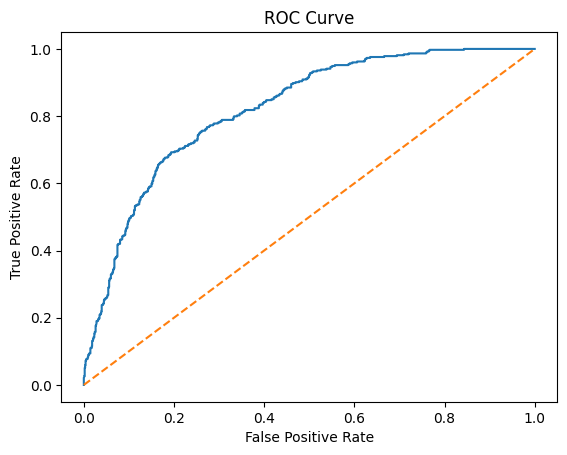

In [ ]:
fpr, tpr, threshold = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr)
plt.plot([0,1],linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

The ROC curve is well above the diagonal reference line, showing that the logistic regression model can distinguish between customers who are likely to churn and those who are likely to stay substantially better than random guessing.

## Understand which facrors influence churn

In [ ]:
coefficients = pd.DataFrame(
    {
        'Feature': X.columns,
        'Coefficient': model.coef_[0]
    }
)
coefficients = coefficients.sort_values('Coefficient', ascending=False)

coefficients.head(10)

,Feature,Coefficient
7041,InternetService_Fiber optic,0.421034
7059,PaymentMethod_Electronic check,0.381625
7057,PaperlessBilling_Yes,0.230116
2,MonthlyCharges,0.190368
0,SeniorCitizen,0.185933
701,customerID_1029-QFBEN,0.154252
4853,customerID_6849-WLEYG,0.151293
5339,customerID_7551-JOHTI,0.146257
3447,customerID_4895-TMWIR,0.145112
3908,customerID_5510-BOIUJ,0.144063


### A positive coefficient means:
### Higher value of this feature is associated with a higher probability of churn

In [ ]:
coefficients.tail(10)

,Feature,Coefficient
7043,OnlineSecurity_No internet service,-0.163061
7036,Partner_Yes,-0.172104
7037,Dependents_Yes,-0.186734
7046,OnlineBackup_Yes,-0.196564
7050,TechSupport_Yes,-0.301709
7044,OnlineSecurity_Yes,-0.314599
7055,Contract_One year,-0.327093
3,Total Charges,-0.366672
7056,Contract_Two year,-0.375437
1,tenure,-0.538615


### A negative coefficient means:

### Higher value presence of this feature is associated with a lower probability of churn
